# Traductor Español-Inglés / Inglés-Español mediante Transformer

## Integrantes
- Vicente Alonso Fuentes Lagos
- Marlon Gabriel Abreu Galviz

## Objetivo

Desarrollar un modelo de traducción automática capaz de trabajar en las direcciones Español → Inglés e Inglés → Español utilizando una arquitectura Transformer.

El modelo será construido y entrenado utilizando TensorFlow/Keras, sin utilizar modelos de traducción preentrenados.

La arquitectura incorporará Encoder, Decoder, codificación posicional y mecanismos Multi-Head Attention.

# 1. Primeros pasos

* **Librerías y semillas**

In [ ]:
import re
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files

from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam


# Semillas
np.random.seed(42)
tf.random.set_seed(42)
keras.utils.set_random_seed(42)


print(
    "TensorFlow:",
    tf.__version__
)

print(
    "GPU:",
    tf.config.list_physical_devices("GPU")
)

TensorFlow: 2.21.0
GPU: []


* **Carga del dataset**

El dataset contiene pares de oraciones Español-Inglés.

Cada registro contiene una oración en inglés, su traducción al español y la fuente correspondiente.

In [ ]:
archivos = files.upload()

nombre_archivo = list(
    archivos.keys()
)[0]

ruta_txt = (
    "/content/"
    + nombre_archivo
)


df_original = pd.read_csv(
    ruta_txt,
    sep="\t",
    header=None,
    names=[
        "Inglés",
        "Español",
        "Fuente"
    ],
    quoting=csv.QUOTE_NONE,
    on_bad_lines="skip"
)


print(
    "Cantidad original de pares:",
    len(df_original)
)


df_original.head()

Saving spa.txt to spa (1).txt
Cantidad original de pares: 144215


,Inglés,Español,Fuente
0,Go.,Ve.,CC-BY 2.0 (France) Attribution: tatoeba.org #2...
1,Go.,Vete.,CC-BY 2.0 (France) Attribution: tatoeba.org #2...
2,Go.,Vaya.,CC-BY 2.0 (France) Attribution: tatoeba.org #2...
3,Go.,Váyase.,CC-BY 2.0 (France) Attribution: tatoeba.org #2...
4,Go.,Id.,CC-BY 2.0 (France) Attribution: tatoeba.org #2...


# 2. Exploración y selección de datos

* **Validación del largo de las oraciones**

Las oraciones deben contener entre 3 y 20 palabras y tener un máximo de 100 caracteres.

La restricción se aplica tanto al Español como al Inglés.

In [ ]:
def contar_palabras(texto):

    return len(
        str(texto).split()
    )


def validar_oracion(texto):

    palabras = contar_palabras(
        texto
    )

    caracteres = len(
        str(texto)
    )

    return (
        3 <= palabras <= 20
        and caracteres <= 100
    )


# Eliminar nulos
df = df_original.dropna(
    subset=[
        "Español",
        "Inglés"
    ]
).copy()


# Eliminar duplicados
df = df.drop_duplicates(
    subset=[
        "Español",
        "Inglés"
    ]
)


# Aplicar restricciones
df = df[
    df["Español"].apply(
        validar_oracion
    )
    &
    df["Inglés"].apply(
        validar_oracion
    )
].copy()


print(
    "Pares válidos:",
    len(df)
)

Pares válidos: 135311


* **Selección de datos**

Se seleccionan 10.000 pares válidos de forma aleatoria.

Se utiliza una semilla fija para trabajar con la misma muestra en cada ejecución y mantener condiciones comparables con el modelo recurrente.

In [ ]:
CANTIDAD_DATOS = 10000


df = df.sample(
    n=min(
        CANTIDAD_DATOS,
        len(df)
    ),
    random_state=42
).reset_index(
    drop=True
)


print(
    "Cantidad de pares utilizados:",
    len(df)
)


df[
    [
        "Español",
        "Inglés"
    ]
].head(10)

Cantidad de pares utilizados: 10000


,Español,Inglés
0,Serás una madre maravillosa.,You'll be a wonderful mother.
1,Salvaron a todos.,Everyone was saved.
2,Quiero que trabajes más.,I want you to work harder.
3,Hay una fina línea entre lo aceptable y lo ina...,There's a fine line between what's acceptable ...
4,Él no quería decepcionar a su madre.,He didn't want to disappoint his mother.
5,Hoy es el gran día.,Today's the big day.
6,Yo la quiero y ella me quiere.,I love her and she loves me.
7,Tom siempre bebe por lo menos tres tazas de ca...,Tom always drinks at least three cups of coffe...
8,Se merece el castigo.,He deserves the punishment.
9,A Tom no le gusta quedarse en casa.,Tom doesn't like to stay at home.


* **Distribución del largo de las oraciones**

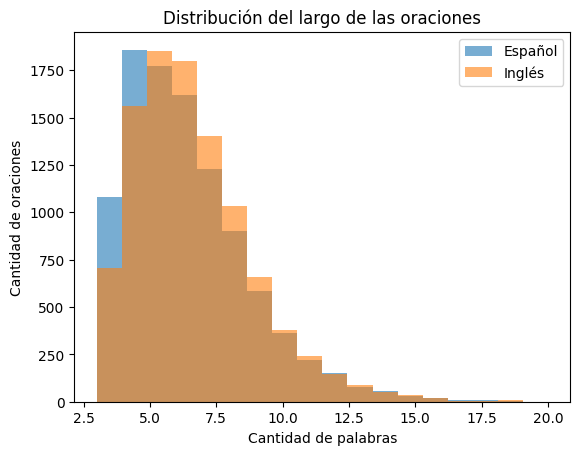

In [ ]:
df["Palabras Español"] = df[
    "Español"
].apply(
    contar_palabras
)


df["Palabras Inglés"] = df[
    "Inglés"
].apply(
    contar_palabras
)


plt.hist(
    df["Palabras Español"],
    bins=18,
    alpha=0.6,
    label="Español"
)

plt.hist(
    df["Palabras Inglés"],
    bins=18,
    alpha=0.6,
    label="Inglés"
)

plt.xlabel(
    "Cantidad de palabras"
)

plt.ylabel(
    "Cantidad de oraciones"
)

plt.title(
    "Distribución del largo de las oraciones"
)

plt.legend()
plt.show()

Las oraciones utilizadas se encuentran dentro del rango establecido de 3 a 20 palabras, por lo que el largo máximo definido es adecuado para preparar las secuencias.

# 3. Preparación de los datos

* **Limpieza del texto**

Las oraciones se convierten a minúsculas y se eliminan signos de puntuación para mantener una representación uniforme antes de la tokenización.

In [ ]:
def limpiar_texto(texto):

    texto = str(
        texto
    ).lower().strip()


    texto = re.sub(
        r"[^a-záéíóúüñ\s]",
        "",
        texto
    )


    texto = re.sub(
        r"\s+",
        " ",
        texto
    )


    return texto


df["Español limpio"] = df[
    "Español"
].apply(
    limpiar_texto
)


df["Inglés limpio"] = df[
    "Inglés"
].apply(
    limpiar_texto
)


df[
    [
        "Español limpio",
        "Inglés limpio"
    ]
].head()

,Español limpio,Inglés limpio
0,serás una madre maravillosa,youll be a wonderful mother
1,salvaron a todos,everyone was saved
2,quiero que trabajes más,i want you to work harder
3,hay una fina línea entre lo aceptable y lo ina...,theres a fine line between whats acceptable an...
4,él no quería decepcionar a su madre,he didnt want to disappoint his mother


* **Separación de datos**

Los datos se dividen en:

- 70% entrenamiento.
- 15% validación.
- 15% prueba.

El conjunto de prueba se reservará para evaluar finalmente la calidad del modelo.

In [ ]:
df_train, df_temporal = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)


df_val, df_test = train_test_split(
    df_temporal,
    test_size=0.50,
    random_state=42
)


df_train = df_train.reset_index(
    drop=True
)

df_val = df_val.reset_index(
    drop=True
)

df_test = df_test.reset_index(
    drop=True
)


print(
    "Entrenamiento:",
    len(df_train)
)

print(
    "Validación:",
    len(df_val)
)

print(
    "Prueba:",
    len(df_test)
)

Entrenamiento: 7000
Validación: 1500
Prueba: 1500


* **Tokenización y Padding**

Las palabras deben convertirse a valores numéricos antes de ser utilizadas por el Transformer.

El vocabulario se construye únicamente utilizando los datos de entrenamiento.

Las oraciones de destino incorporan startseq y endseq para indicar el inicio y final de cada traducción.

In [ ]:
MAX_PALABRAS = 20


def preparar_direccion(
    df_train,
    df_val,
    df_test,
    columna_origen,
    columna_destino
):

    origen_train = df_train[
        columna_origen
    ].tolist()

    origen_val = df_val[
        columna_origen
    ].tolist()

    origen_test = df_test[
        columna_origen
    ].tolist()


    destino_train = [
        "startseq "
        + texto
        + " endseq"

        for texto in df_train[
            columna_destino
        ]
    ]


    destino_val = [
        "startseq "
        + texto
        + " endseq"

        for texto in df_val[
            columna_destino
        ]
    ]


    destino_test = [
        "startseq "
        + texto
        + " endseq"

        for texto in df_test[
            columna_destino
        ]
    ]


    tokenizer_origen = Tokenizer(
        filters="",
        oov_token="oov"
    )


    tokenizer_destino = Tokenizer(
        filters="",
        oov_token="oov"
    )


    tokenizer_origen.fit_on_texts(
        origen_train
    )


    tokenizer_destino.fit_on_texts(
        destino_train
    )


    max_origen = MAX_PALABRAS

    max_destino = (
        MAX_PALABRAS + 2
    )


    def convertir(
        origen,
        destino
    ):

        x = tokenizer_origen.texts_to_sequences(
            origen
        )

        y = tokenizer_destino.texts_to_sequences(
            destino
        )


        x = pad_sequences(
            x,
            maxlen=max_origen,
            padding="post",
            truncating="post"
        )


        y = pad_sequences(
            y,
            maxlen=max_destino,
            padding="post",
            truncating="post"
        )


        decoder_input = y[
            :,
            :-1
        ]


        decoder_target = y[
            :,
            1:
        ]


        pesos = (
            decoder_target != 0
        ).astype(
            "float32"
        )


        return (
            x,
            decoder_input,
            decoder_target,
            pesos
        )


    return {

        "tokenizer_origen":
            tokenizer_origen,

        "tokenizer_destino":
            tokenizer_destino,

        "max_origen":
            max_origen,

        "max_destino":
            max_destino,

        "vocab_origen":
            len(
                tokenizer_origen.word_index
            ) + 1,

        "vocab_destino":
            len(
                tokenizer_destino.word_index
            ) + 1,

        "train":
            convertir(
                origen_train,
                destino_train
            ),

        "val":
            convertir(
                origen_val,
                destino_val
            ),

        "test":
            convertir(
                origen_test,
                destino_test
            )
    }

* **Preparación de ambas direcciones**

In [ ]:
datos_es_en = preparar_direccion(
    df_train,
    df_val,
    df_test,
    "Español limpio",
    "Inglés limpio"
)


datos_en_es = preparar_direccion(
    df_train,
    df_val,
    df_test,
    "Inglés limpio",
    "Español limpio"
)


print(
    "Vocabulario Español:",
    datos_es_en[
        "vocab_origen"
    ]
)

print(
    "Vocabulario Inglés:",
    datos_es_en[
        "vocab_destino"
    ]
)

Vocabulario Español: 6308
Vocabulario Inglés: 4179


# 4. Arquitectura Transformer

El Transformer utiliza mecanismos de atención para analizar las relaciones entre las palabras de una secuencia.

Los principales componentes utilizados son:

- **Embedding:** representa cada palabra mediante un vector numérico.
- **Información posicional:** indica la posición de cada palabra dentro de la oración.
- **Encoder:** analiza la oración de entrada mediante autoatención.
- **Multi-Head Attention:** permite observar diferentes relaciones entre las palabras.
- **Decoder:** genera progresivamente la traducción.
- **Cross-Attention:** permite al Decoder utilizar la información generada por el Encoder.
- **Dense y Softmax:** calculan la probabilidad de cada palabra posible.

* **Embedding posicional**

A diferencia de una RNN, el Transformer no utiliza recurrencia para conocer el orden de las palabras.

Por esta razón se combina el Embedding de cada palabra con una representación de su posición.

In [ ]:
class PositionalEmbedding(
    layers.Layer
):

    def __init__(
        self,
        vocab_size,
        d_model,
        max_length
    ):

        super().__init__()


        self.token_embedding = (
            layers.Embedding(
                vocab_size,
                d_model,
                mask_zero=True
            )
        )


        self.position_embedding = (
            layers.Embedding(
                max_length,
                d_model
            )
        )


    def call(
        self,
        inputs
    ):

        longitud = tf.shape(
            inputs
        )[-1]


        posiciones = tf.range(
            start=0,
            limit=longitud,
            delta=1
        )


        tokens = self.token_embedding(
            inputs
        )


        posiciones = (
            self.position_embedding(
                posiciones
            )
        )


        return (
            tokens
            + posiciones
        )

* **Encoder**

El Encoder utiliza Multi-Head Self-Attention para identificar relaciones entre las palabras de la oración de entrada.

Después de la atención se utiliza una red Dense, conexiones residuales y normalización.

In [ ]:
class EncoderTransformer(
    layers.Layer
):

    def __init__(
        self,
        d_model,
        num_heads,
        dff,
        dropout=0.1
    ):

        super().__init__()


        self.atencion = (
            layers.MultiHeadAttention(
                num_heads=
                num_heads,

                key_dim=
                d_model // num_heads
            )
        )


        self.ffn = keras.Sequential([
            layers.Dense(
                dff,
                activation="relu"
            ),

            layers.Dense(
                d_model
            )
        ])


        self.norm1 = (
            layers.LayerNormalization(
                epsilon=1e-6
            )
        )


        self.norm2 = (
            layers.LayerNormalization(
                epsilon=1e-6
            )
        )


        self.dropout1 = (
            layers.Dropout(
                dropout
            )
        )


        self.dropout2 = (
            layers.Dropout(
                dropout
            )
        )


    def call(
        self,
        x,
        padding_mask=None,
        training=False
    ):

        atencion = self.atencion(
            query=x,
            value=x,
            key=x,
            attention_mask=
            padding_mask,
            training=training
        )


        x = self.norm1(
            x
            +
            self.dropout1(
                atencion,
                training=training
            )
        )


        ffn = self.ffn(
            x,
            training=training
        )


        x = self.norm2(
            x
            +
            self.dropout2(
                ffn,
                training=training
            )
        )


        return x

* **Decoder**

El Decoder utiliza autoatención causal para generar la traducción sin observar palabras futuras.

Posteriormente utiliza Cross-Attention para relacionar la traducción que está generando con la información procesada por el Encoder.

In [ ]:
class DecoderTransformer(
    layers.Layer
):

    def __init__(
        self,
        d_model,
        num_heads,
        dff,
        dropout=0.1
    ):

        super().__init__()


        self.autoatencion = (
            layers.MultiHeadAttention(
                num_heads=
                num_heads,

                key_dim=
                d_model // num_heads
            )
        )


        self.atencion_cruzada = (
            layers.MultiHeadAttention(
                num_heads=
                num_heads,

                key_dim=
                d_model // num_heads
            )
        )


        self.ffn = keras.Sequential([
            layers.Dense(
                dff,
                activation="relu"
            ),

            layers.Dense(
                d_model
            )
        ])


        self.norm1 = layers.LayerNormalization(
            epsilon=1e-6
        )

        self.norm2 = layers.LayerNormalization(
            epsilon=1e-6
        )

        self.norm3 = layers.LayerNormalization(
            epsilon=1e-6
        )


        self.dropout1 = layers.Dropout(
            dropout
        )

        self.dropout2 = layers.Dropout(
            dropout
        )

        self.dropout3 = layers.Dropout(
            dropout
        )


    def call(
        self,
        x,
        encoder_output,
        decoder_mask=None,
        encoder_mask=None,
        training=False
    ):

        # Autoatención causal
        atencion1 = self.autoatencion(
            query=x,
            value=x,
            key=x,
            attention_mask=
            decoder_mask,
            use_causal_mask=True,
            training=training
        )


        x = self.norm1(
            x
            +
            self.dropout1(
                atencion1,
                training=training
            )
        )


        # Cross-Attention
        atencion2 = (
            self.atencion_cruzada(
                query=x,
                value=encoder_output,
                key=encoder_output,
                attention_mask=
                encoder_mask,
                training=training
            )
        )


        x = self.norm2(
            x
            +
            self.dropout2(
                atencion2,
                training=training
            )
        )


        ffn = self.ffn(
            x,
            training=training
        )


        x = self.norm3(
            x
            +
            self.dropout3(
                ffn,
                training=training
            )
        )


        return x

* **Construcción del Transformer**

Se utilizará un Encoder y un Decoder debido al tamaño reducido de las oraciones.

La configuración base utiliza Embedding de 64 dimensiones, cuatro cabezas de atención, una red interna de 128 unidades y Dropout de 0,1.

In [ ]:
def crear_transformer(
    vocab_origen,
    vocab_destino,
    max_origen,
    max_destino,
    d_model=64,
    num_heads=4,
    dff=128,
    dropout=0.1,
    learning_rate=0.001
):

    entrada_encoder = Input(
        shape=(
            max_origen,
        ),
        dtype="int32"
    )


    entrada_decoder = Input(
        shape=(
            max_destino - 1,
        ),
        dtype="int32"
    )


    # Máscara Encoder
    encoder_mask = layers.Lambda(
        lambda x:
        tf.expand_dims(
            tf.not_equal(
                x,
                0
            ),
            axis=1
        )
    )(
        entrada_encoder
    )


    # Máscara Decoder
    decoder_mask = layers.Lambda(
        lambda x:
        tf.expand_dims(
            tf.not_equal(
                x,
                0
            ),
            axis=1
        )
    )(
        entrada_decoder
    )


    # Embedding Encoder
    encoder_x = PositionalEmbedding(
        vocab_origen,
        d_model,
        max_origen
    )(
        entrada_encoder
    )


    encoder_output = EncoderTransformer(
        d_model,
        num_heads,
        dff,
        dropout
    )(
        encoder_x,
        padding_mask=
        encoder_mask
    )


    # Embedding Decoder
    decoder_x = PositionalEmbedding(
        vocab_destino,
        d_model,
        max_destino
    )(
        entrada_decoder
    )


    decoder_output = DecoderTransformer(
        d_model,
        num_heads,
        dff,
        dropout
    )(
        decoder_x,
        encoder_output,
        decoder_mask=
        decoder_mask,
        encoder_mask=
        encoder_mask
    )


    salida = Dense(
        vocab_destino,
        activation="softmax"
    )(
        decoder_output
    )


    modelo = keras.Model(
        [
            entrada_encoder,
            entrada_decoder
        ],
        salida
    )


    modelo.compile(
        optimizer=Adam(
            learning_rate=
            learning_rate
        ),

        loss=
        "sparse_categorical_crossentropy",

        weighted_metrics=[
            keras.metrics
            .SparseCategoricalAccuracy(
                name="accuracy"
            )
        ]
    )


    return modelo

# 5. Evaluación del modelo

Para evaluar las diferentes configuraciones se utilizarán:

- Accuracy.
- Precision.
- Recall.
- F1-Score.
- Loss.

Las posiciones utilizadas únicamente como Padding serán ignoradas.

In [ ]:
def evaluar_transformer(
    modelo,
    datos,
    batch_size=64
):

    x_encoder, x_decoder, y_real, pesos = datos


    resultado = modelo.evaluate(
        [
            x_encoder,
            x_decoder
        ],
        y_real,
        sample_weight=
        pesos,
        batch_size=
        batch_size,
        verbose=0,
        return_dict=True
    )


    reales_total = []
    predichos_total = []


    for inicio in range(
        0,
        len(x_encoder),
        batch_size
    ):

        fin = (
            inicio
            + batch_size
        )


        predicciones = modelo(
            [
                x_encoder[
                    inicio:fin
                ],

                x_decoder[
                    inicio:fin
                ]
            ],

            training=False
        )


        y_pred = tf.argmax(
            predicciones,
            axis=-1
        ).numpy()


        y_batch = y_real[
            inicio:fin
        ]


        mascara = (
            y_batch != 0
        )


        reales_total.append(
            y_batch[
                mascara
            ]
        )


        predichos_total.append(
            y_pred[
                mascara
            ]
        )


    reales = np.concatenate(
        reales_total
    )


    predichos = np.concatenate(
        predichos_total
    )


    return {

        "Loss":
            resultado[
                "loss"
            ],

        "Accuracy":
            accuracy_score(
                reales,
                predichos
            ),

        "Precision":
            precision_score(
                reales,
                predichos,
                average="weighted",
                zero_division=0
            ),

        "Recall":
            recall_score(
                reales,
                predichos,
                average="weighted",
                zero_division=0
            ),

        "F1-Score":
            f1_score(
                reales,
                predichos,
                average="weighted",
                zero_division=0
            )
    }

# 6. Comparación de configuraciones

Para mantener el análisis compacto se compararán cuatro configuraciones.

La configuración base utiliza cuatro cabezas de atención, Learning Rate de 0,001 y Batch Size de 64.

Las demás configuraciones cambian un parámetro respecto a la base, permitiendo observar su efecto sobre el rendimiento.

In [ ]:
x_train, dec_train, y_train, w_train = (
    datos_es_en["train"]
)

x_val, dec_val, y_val, w_val = (
    datos_es_en["val"]
)


# Usar una muestra más pequeña solo para los experimentos
CANTIDAD_TRAIN_EXP = 3000
CANTIDAD_VAL_EXP = 750


x_train_exp = x_train[
    :CANTIDAD_TRAIN_EXP
]

dec_train_exp = dec_train[
    :CANTIDAD_TRAIN_EXP
]

y_train_exp = y_train[
    :CANTIDAD_TRAIN_EXP
]

w_train_exp = w_train[
    :CANTIDAD_TRAIN_EXP
]


x_val_exp = x_val[
    :CANTIDAD_VAL_EXP
]

dec_val_exp = dec_val[
    :CANTIDAD_VAL_EXP
]

y_val_exp = y_val[
    :CANTIDAD_VAL_EXP
]

w_val_exp = w_val[
    :CANTIDAD_VAL_EXP
]


datos_val_exp = (
    x_val_exp,
    dec_val_exp,
    y_val_exp,
    w_val_exp
)


print(
    "Datos de entrenamiento para experimentos:",
    len(x_train_exp)
)

print(
    "Datos de validación para experimentos:",
    len(x_val_exp)
)


configuraciones = [

    {
        "Configuración": "Base",
        "Cabezas": 4,
        "Learning Rate": 0.001,
        "Batch Size": 64
    },

    {
        "Configuración": "2 cabezas",
        "Cabezas": 2,
        "Learning Rate": 0.001,
        "Batch Size": 64
    },

    {
        "Configuración": "LR 0.0005",
        "Cabezas": 4,
        "Learning Rate": 0.0005,
        "Batch Size": 64
    },

    {
        "Configuración": "Batch 32",
        "Cabezas": 4,
        "Learning Rate": 0.001,
        "Batch Size": 32
    }
]


resultados = []


for config in configuraciones:

    print(
        "\nEntrenando:",
        config["Configuración"]
    )


    keras.backend.clear_session()
    keras.utils.set_random_seed(42)


    modelo = crear_transformer(

        datos_es_en["vocab_origen"],
        datos_es_en["vocab_destino"],
        datos_es_en["max_origen"],
        datos_es_en["max_destino"],

        d_model=64,

        num_heads=
        config["Cabezas"],

        dff=128,

        dropout=0.1,

        learning_rate=
        config["Learning Rate"]
    )


    modelo.fit(

        [
            x_train_exp,
            dec_train_exp
        ],

        y_train_exp,

        sample_weight=
        w_train_exp,

        validation_data=(
            [
                x_val_exp,
                dec_val_exp
            ],
            y_val_exp,
            w_val_exp
        ),

        epochs=3,

        batch_size=
        config["Batch Size"],

        verbose=1
    )


    metricas = evaluar_transformer(
        modelo,
        datos_val_exp,

        batch_size=
        config["Batch Size"]
    )


    resultados.append({
        **config,
        **metricas
    })


tabla_configuraciones = pd.DataFrame(
    resultados
)


display(
    tabla_configuraciones
)

Datos de entrenamiento para experimentos: 3000
Datos de validación para experimentos: 750

Entrenando: Base
Epoch 1/3
47/47 ━━━━━━━━━━━━━━━━━━━━ 27s 404ms/step - accuracy: 0.1391 - loss: 2.4759 - val_accuracy: 0.1639 - val_loss: 2.0735
Epoch 2/3
47/47 ━━━━━━━━━━━━━━━━━━━━ 20s 423ms/step - accuracy: 0.1706 - loss: 1.9349 - val_accuracy: 0.1925 - val_loss: 1.8562
Epoch 3/3
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 390ms/step - accuracy: 0.2345 - loss: 1.7170 - val_accuracy: 0.2565 - val_loss: 1.7082

Entrenando: 2 cabezas
Epoch 1/3
47/47 ━━━━━━━━━━━━━━━━━━━━ 28s 410ms/step - accuracy: 0.1409 - loss: 2.4757 - val_accuracy: 0.1639 - val_loss: 2.0750
Epoch 2/3
47/47 ━━━━━━━━━━━━━━━━━━━━ 20s 426ms/step - accuracy: 0.1720 - loss: 1.9357 - val_accuracy: 0.1950 - val_loss: 1.8524
Epoch 3/3
47/47 ━━━━━━━━━━━━━━━━━━━━ 19s 388ms/step - accuracy: 0.2398 - loss: 1.7145 - val_accuracy: 0.2594 - val_loss: 1.7020

Entrenando: LR 0.0005
Epoch 1/3
47/47 ━━━━━━━━━━━━━━━━━━━━ 28s 407ms/step - accuracy: 0.1285 - loss:

,Configuración,Cabezas,Learning Rate,Batch Size,Loss,Accuracy,Precision,Recall,F1-Score
0,Base,4,0.0010,64,1.708211,0.256514,0.096545,0.256514,0.134938
1,2 cabezas,2,0.0010,64,1.701977,0.259450,0.099108,0.259450,0.138754
2,LR 0.0005,4,0.0005,64,1.935691,0.175229,0.048450,0.175229,0.061583
3,Batch 32,4,0.0010,32,1.570111,0.304220,0.166472,0.304220,0.202981


* **Comparación gráfica**

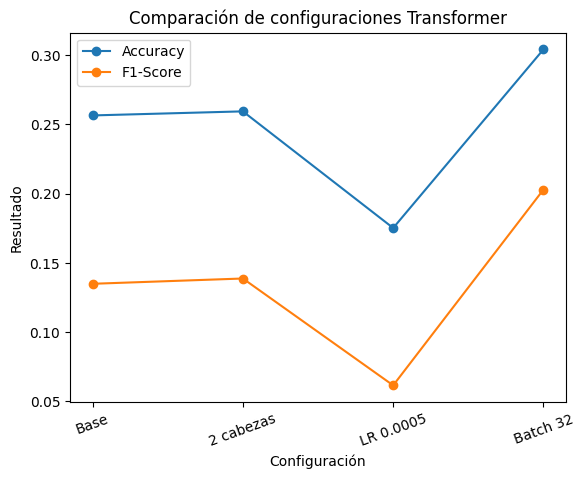

In [ ]:
plt.plot(
    tabla_configuraciones[
        "Configuración"
    ],

    tabla_configuraciones[
        "Accuracy"
    ],

    marker="o",

    label="Accuracy"
)


plt.plot(
    tabla_configuraciones[
        "Configuración"
    ],

    tabla_configuraciones[
        "F1-Score"
    ],

    marker="o",

    label="F1-Score"
)


plt.xlabel(
    "Configuración"
)

plt.ylabel(
    "Resultado"
)

plt.title(
    "Comparación de configuraciones Transformer"
)

plt.xticks(
    rotation=20
)

plt.legend()
plt.show()

La configuración con Batch Size 32 obtuvo el mejor rendimiento, alcanzando mayor Accuracy y F1-Score y una menor pérdida.

Por esta razón se seleccionó esta configuración para entrenar el modelo final.

* **Selección del modelo**

La configuración final se seleccionará considerando principalmente F1-Score y Accuracy.

También se considerará la pérdida obtenida para evitar seleccionar una configuración que presente un comportamiento inestable durante la validación.

In [ ]:
mejor_config = tabla_configuraciones.loc[
    tabla_configuraciones[
        "F1-Score"
    ].idxmax()
]


HEADS_FINAL = int(
    mejor_config[
        "Cabezas"
    ]
)


LR_FINAL = float(
    mejor_config[
        "Learning Rate"
    ]
)


BATCH_FINAL = int(
    mejor_config[
        "Batch Size"
    ]
)


print(
    "Configuración seleccionada:",
    mejor_config[
        "Configuración"
    ]
)

print(
    "Cabezas:",
    HEADS_FINAL
)

print(
    "Learning Rate:",
    LR_FINAL
)

print(
    "Batch Size:",
    BATCH_FINAL
)

print(
    "Accuracy:",
    round(
        mejor_config[
            "Accuracy"
        ],
        4
    )
)

print(
    "F1-Score:",
    round(
        mejor_config[
            "F1-Score"
        ],
        4
    )
)

Configuración seleccionada: Batch 32
Cabezas: 4
Learning Rate: 0.001
Batch Size: 32
Accuracy: 0.3042
F1-Score: 0.203


# 7. Entrenamiento del Transformer final

La configuración seleccionada se vuelve a entrenar desde cero utilizando todos los datos de entrenamiento.

Se utilizarán 6 épocas para permitir un entrenamiento más completo que el utilizado durante la comparación inicial de configuraciones.

Durante el entrenamiento se analizarán las curvas de Accuracy y Loss de entrenamiento y validación para observar la evolución del modelo y detectar posibles señales de sobreajuste.

In [ ]:
keras.backend.clear_session()

keras.utils.set_random_seed(
    42
)


modelo_final_es_en = crear_transformer(

    datos_es_en[
        "vocab_origen"
    ],

    datos_es_en[
        "vocab_destino"
    ],

    datos_es_en[
        "max_origen"
    ],

    datos_es_en[
        "max_destino"
    ],

    d_model=64,

    num_heads=
    HEADS_FINAL,

    dff=128,

    dropout=0.1,

    learning_rate=
    LR_FINAL
)


history_final_es_en = modelo_final_es_en.fit(

    [
        x_train,
        dec_train
    ],

    y_train,

    sample_weight=
    w_train,

    validation_data=(
        [
            x_val,
            dec_val
        ],
        y_val,
        w_val
    ),

    epochs=6,

    batch_size=
    BATCH_FINAL,

    verbose=1
)

Epoch 1/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 54s 210ms/step - accuracy: 0.1967 - loss: 1.9855 - val_accuracy: 0.2746 - val_loss: 1.6673
Epoch 2/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 45s 207ms/step - accuracy: 0.3265 - loss: 1.4646 - val_accuracy: 0.3584 - val_loss: 1.4409
Epoch 3/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 44s 200ms/step - accuracy: 0.4251 - loss: 1.1820 - val_accuracy: 0.4118 - val_loss: 1.3290
Epoch 4/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 82s 201ms/step - accuracy: 0.5142 - loss: 0.9559 - val_accuracy: 0.4480 - val_loss: 1.2658
Epoch 5/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 46s 209ms/step - accuracy: 0.5904 - loss: 0.7709 - val_accuracy: 0.4777 - val_loss: 1.2445
Epoch 6/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 82s 209ms/step - accuracy: 0.6585 - loss: 0.6174 - val_accuracy: 0.4881 - val_loss: 1.2291


* **Evolución del entrenamiento**

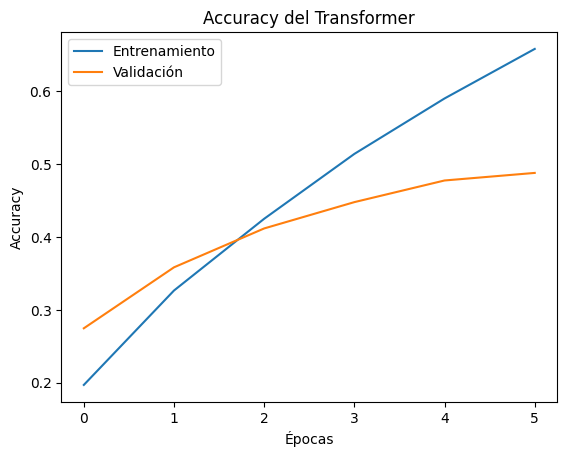

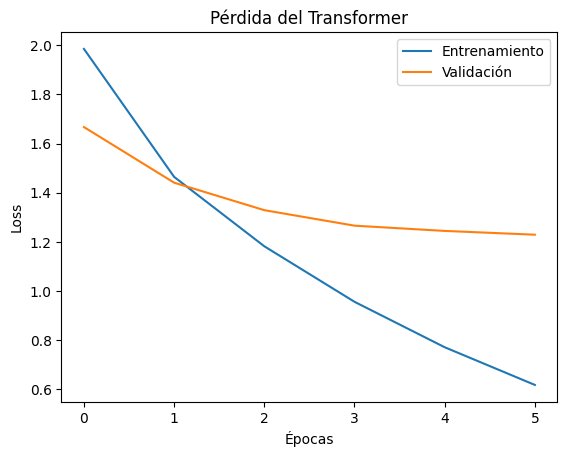

In [ ]:
plt.plot(
    history_final_es_en.history[
        "accuracy"
    ],
    label="Entrenamiento"
)


plt.plot(
    history_final_es_en.history[
        "val_accuracy"
    ],
    label="Validación"
)


plt.xlabel(
    "Épocas"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Accuracy del Transformer"
)

plt.legend()
plt.show()


plt.plot(
    history_final_es_en.history[
        "loss"
    ],
    label="Entrenamiento"
)


plt.plot(
    history_final_es_en.history[
        "val_loss"
    ],
    label="Validación"
)


plt.xlabel(
    "Épocas"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Pérdida del Transformer"
)

plt.legend()
plt.show()

Durante las 6 épocas aumentan tanto el Accuracy de entrenamiento como el de validación, mientras que la pérdida disminuye.

El modelo continúa mejorando hasta la última época, aunque se observa una diferencia creciente entre entrenamiento y validación.

* **Entrenamiento Inglés → Español**

Para realizar traducción en ambas direcciones se utiliza la misma configuración final intercambiando los idiomas de entrada y salida.

In [ ]:
x_train_en, dec_train_en, y_train_en, w_train_en = (
    datos_en_es[
        "train"
    ]
)


x_val_en, dec_val_en, y_val_en, w_val_en = (
    datos_en_es[
        "val"
    ]
)


keras.utils.set_random_seed(
    42
)


modelo_final_en_es = crear_transformer(

    datos_en_es[
        "vocab_origen"
    ],

    datos_en_es[
        "vocab_destino"
    ],

    datos_en_es[
        "max_origen"
    ],

    datos_en_es[
        "max_destino"
    ],

    d_model=64,

    num_heads=
    HEADS_FINAL,

    dff=128,

    dropout=0.1,

    learning_rate=
    LR_FINAL
)


history_final_en_es = modelo_final_en_es.fit(

    [
        x_train_en,
        dec_train_en
    ],

    y_train_en,

    sample_weight=
    w_train_en,

    validation_data=(
        [
            x_val_en,
            dec_val_en
        ],
        y_val_en,
        w_val_en
    ),

    epochs=6,

    batch_size=
    BATCH_FINAL,

    verbose=1
)

Epoch 1/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 70s 287ms/step - accuracy: 0.1702 - loss: 2.0864 - val_accuracy: 0.2375 - val_loss: 1.8081
Epoch 2/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 80s 278ms/step - accuracy: 0.2893 - loss: 1.5863 - val_accuracy: 0.3167 - val_loss: 1.5783
Epoch 3/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 83s 282ms/step - accuracy: 0.3815 - loss: 1.2952 - val_accuracy: 0.3530 - val_loss: 1.4630
Epoch 4/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 82s 284ms/step - accuracy: 0.4571 - loss: 1.0705 - val_accuracy: 0.3902 - val_loss: 1.4000
Epoch 5/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 61s 277ms/step - accuracy: 0.5278 - loss: 0.8826 - val_accuracy: 0.4164 - val_loss: 1.3465
Epoch 6/6
219/219 ━━━━━━━━━━━━━━━━━━━━ 83s 284ms/step - accuracy: 0.5950 - loss: 0.7206 - val_accuracy: 0.4396 - val_loss: 1.3362


* **Visualización del modelo final**

In [ ]:
resumen_modelo = pd.DataFrame({
    "Componente": [
        "Entrada Encoder",
        "Embedding",
        "Encoder",
        "Decoder",
        "Multi-Head Attention",
        "Red interna",
        "Dropout",
        "Salida",
        "Learning Rate",
        "Batch Size",
        "Épocas"
    ],
    "Configuración": [
        "20 palabras",
        "64 dimensiones",
        "1 bloque",
        "1 bloque",
        f"{HEADS_FINAL} cabezas",
        "128 unidades",
        "0.1",
        f"{datos_es_en['vocab_destino']} palabras",
        LR_FINAL,
        BATCH_FINAL,
        6
    ]
})

display(resumen_modelo)

,Componente,Configuración
0,Entrada Encoder,20 palabras
1,Embedding,64 dimensiones
2,Encoder,1 bloque
3,Decoder,1 bloque
4,Multi-Head Attention,4 cabezas
5,Red interna,128 unidades
6,Dropout,0.1
7,Salida,4179 palabras
8,Learning Rate,0.001
9,Batch Size,32


* **Interpretación**

El modelo final utiliza una arquitectura Encoder-Decoder con 4 cabezas de atención, Embedding de 64 dimensiones y una red interna de 128 unidades.

La configuración seleccionada utiliza Learning Rate de 0,001, Batch Size de 32 y 6 épocas de entrenamiento.

# 8. Evaluación final

Los modelos finales se evalúan utilizando el conjunto de prueba mediante Accuracy, Precision, Recall, F1-Score y Loss.

In [ ]:
metricas_es_en = evaluar_transformer(

    modelo_final_es_en,

    datos_es_en[
        "test"
    ],

    batch_size=
    BATCH_FINAL
)


metricas_en_es = evaluar_transformer(

    modelo_final_en_es,

    datos_en_es[
        "test"
    ],

    batch_size=
    BATCH_FINAL
)


tabla_metricas_final = pd.DataFrame([

    {
        "Dirección":
            "Español → Inglés",

        **metricas_es_en
    },

    {
        "Dirección":
            "Inglés → Español",

        **metricas_en_es
    }

])


tabla_metricas_final

,Dirección,Loss,Accuracy,Precision,Recall,F1-Score
0,Español → Inglés,1.227608,0.492269,0.457658,0.492269,0.459600
1,Inglés → Español,1.336927,0.441168,0.369995,0.441168,0.388913


### Interpretación de las métricas finales

El modelo obtuvo mejores resultados en Español → Inglés, con Accuracy de 0,4923 y F1-Score de 0,4596.

En Inglés → Español alcanzó Accuracy de 0,4412 y F1-Score de 0,3889.

Esto indica un mejor desempeño general en la dirección Español → Inglés.

# 9. Pruebas de traducción

Se seleccionan cinco oraciones completas del conjunto de prueba.

Para cada ejemplo se compara la traducción esperada con la traducción generada por el Transformer.

In [ ]:
def traducir_transformer(
    frase,
    datos,
    modelo
):

    frase = limpiar_texto(
        frase
    )


    entrada = datos[
        "tokenizer_origen"
    ].texts_to_sequences(
        [frase]
    )


    entrada = pad_sequences(
        entrada,

        maxlen=
        datos[
            "max_origen"
        ],

        padding="post",

        truncating="post"
    )


    inicio = datos[
        "tokenizer_destino"
    ].word_index[
        "startseq"
    ]


    fin = datos[
        "tokenizer_destino"
    ].word_index[
        "endseq"
    ]


    tokens = [
        inicio
    ]


    palabras = []


    for _ in range(
        datos[
            "max_destino"
        ] - 1
    ):


        decoder_input = pad_sequences(
            [
                tokens
            ],

            maxlen=
            datos[
                "max_destino"
            ] - 1,

            padding="post",

            truncating="post"
        )


        prediccion = modelo.predict(
            [
                entrada,
                decoder_input
            ],
            verbose=0
        )


        posicion = (
            len(tokens)
            - 1
        )


        siguiente = int(
            np.argmax(
                prediccion[
                    0,
                    posicion
                ]
            )
        )


        if siguiente in [
            0,
            fin
        ]:

            break


        palabra = datos[
            "tokenizer_destino"
        ].index_word.get(
            siguiente,
            "oov"
        )


        palabras.append(
            palabra
        )


        tokens.append(
            siguiente
        )


    return " ".join(
        palabras
    )

* **Español → Inglés**

In [ ]:
muestra = df_test.sample(
    n=5,
    random_state=42
)


for _, fila in muestra.iterrows():


    traduccion = traducir_transformer(

        fila[
            "Español"
        ],

        datos_es_en,

        modelo_final_es_en
    )


    print(
        "Entrada:",
        fila[
            "Español"
        ]
    )

    print(
        "Esperado:",
        fila[
            "Inglés"
        ]
    )

    print(
        "Obtenido:",
        traduccion
    )

    print(
        "-" * 60
    )

Entrada: La mujer está desnuda.
Esperado: The woman is naked.
Obtenido: the woman is busy
------------------------------------------------------------
Entrada: Tom sangra otra vez.
Esperado: Tom is bleeding again.
Obtenido: tom your time again
------------------------------------------------------------
Entrada: Mi novia es muy hermosa.
Esperado: My girlfriend is very beautiful.
Obtenido: my girlfriend is very well be very well
------------------------------------------------------------
Entrada: No llevó mucho tiempo.
Esperado: That didn't take long.
Obtenido: he didnt be very long
------------------------------------------------------------
Entrada: Venga, prueba otra vez.
Esperado: OK, try again.
Obtenido: come on another one
------------------------------------------------------------


* **Inglés → Español**

In [ ]:
for _, fila in muestra.iterrows():


    traduccion = traducir_transformer(

        fila[
            "Inglés"
        ],

        datos_en_es,

        modelo_final_en_es
    )


    print(
        "Entrada:",
        fila[
            "Inglés"
        ]
    )

    print(
        "Esperado:",
        fila[
            "Español"
        ]
    )

    print(
        "Obtenido:",
        traduccion
    )

    print(
        "-" * 60
    )

Entrada: The woman is naked.
Esperado: La mujer está desnuda.
Obtenido: el mujer está en peligro
------------------------------------------------------------
Entrada: Tom is bleeding again.
Esperado: Tom sangra otra vez.
Obtenido: tom está seguro
------------------------------------------------------------
Entrada: My girlfriend is very beautiful.
Esperado: Mi novia es muy hermosa.
Obtenido: mi novia es muy difícil
------------------------------------------------------------
Entrada: That didn't take long.
Esperado: No llevó mucho tiempo.
Obtenido: eso no podía soportar tiempo
------------------------------------------------------------
Entrada: OK, try again.
Esperado: Venga, prueba otra vez.
Obtenido: pensá en nuevo
------------------------------------------------------------


#10. Análisis de las traducciones

El Transformer reconoce vocabulario y estructuras relevantes en ambos idiomas, pero todavía comete errores de significado, repeticiones y problemas gramaticales.

Los resultados indican que el modelo aprendió relaciones entre Español e Inglés, aunque los 10.000 pares de entrenamiento y el tamaño de la arquitectura limitan la calidad final.

#11. Posibles mejoras

Se podría mejorar el modelo utilizando más datos, aumentando la capacidad del Encoder y Decoder o probando otras configuraciones de atención.

También se podrían entrenar más épocas utilizando Early Stopping para evitar sobreentrenamiento.



#12. Conclusión

Se desarrolló un Transformer para traducción Español-Inglés e Inglés-Español utilizando Encoder, Decoder y mecanismos de atención.

La mejor configuración utilizó 4 cabezas de atención, Learning Rate de 0,001 y Batch Size de 32.

El modelo obtuvo mejores resultados en Español → Inglés, aunque todavía presenta errores semánticos y gramaticales.

Como mejora futura se podría aumentar la cantidad de datos y la capacidad de la arquitectura.